# 15 — Non-inferiority of compressed CLP

Test whether compressed context probing is practically non-inferior to DenseCLP.

For compressed method \(C\) and dense method \(D\), define paired split-level AUROC difference

\[
d_s = AUROC_s(C)-AUROC_s(D).
\]

Primary margin:

\[
\delta = 0.01.
\]

Sensitivity margins:

\[
\delta\in\{0.005,0.01,0.02\}.
\]

We test Endpoint \(L_N\) and Geometric probing against DenseCLP for \(N\in\{32,64,128,256\}\) using notebook 14's already-computed split results.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

cwd = Path.cwd().resolve()
ROOT = cwd.parent if cwd.name == "experiments" else cwd
RESULTS = ROOT / "results"
FIGURES = ROOT / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

SPLIT_PATH = RESULTS / "max_context_scaling_splits.csv"
assert SPLIT_PATH.exists(), SPLIT_PATH

splits = pd.read_csv(SPLIT_PATH)
display(splits.head())
print("rows:", len(splits))


,scorer,N,seed,method,m,best_C,auroc
0,Qwen3-0.6B,32,0,Endpoint,1,0.001,0.878889
1,Qwen3-0.6B,32,0,Geometric,3,10.000,0.894444
2,Qwen3-0.6B,32,0,Dense,25,10.000,0.874444
3,Qwen3-0.6B,32,1,Endpoint,1,0.001,0.886667
4,Qwen3-0.6B,32,1,Geometric,3,10.000,0.900000


rows: 480


In [2]:
wide = splits.pivot_table(
    index=["scorer","N","seed"],
    columns="method",
    values="auroc",
)

rows = []
for (scorer, N), sub in wide.groupby(level=["scorer","N"]):
    sub = sub.reset_index()
    for method in ["Endpoint","Geometric"]:
        d = sub[method] - sub["Dense"]
        for seed, val in zip(sub["seed"], d):
            rows.append({
                "scorer": scorer,
                "N": int(N),
                "seed": int(seed),
                "method": method,
                "delta_vs_dense": float(val),
            })

paired = pd.DataFrame(rows)
display(paired.head())


,scorer,N,seed,method,delta_vs_dense
0,GPT-2,32,0,Endpoint,0.021111
1,GPT-2,32,1,Endpoint,-0.024444
2,GPT-2,32,2,Endpoint,-0.018889
3,GPT-2,32,3,Endpoint,-0.004444
4,GPT-2,32,4,Endpoint,-0.006667


## Split-level non-inferiority diagnostics

Because the 20 outer splits overlap in their documents, the following should be interpreted as robustness diagnostics rather than independent-sample guarantees.

We report:
- paired mean difference,
- paired bootstrap 95% interval,
- bootstrap probability that the mean exceeds \(-\delta\),
- a one-sided sign-flip test at the non-inferiority boundary.


In [3]:
BOOTSTRAPS = 20000
PERMUTATIONS = 50000
MARGINS = [0.005, 0.01, 0.02]
RNG_SEED = 1501

def bootstrap_mean_ci(d, n_boot=BOOTSTRAPS, seed=RNG_SEED):
    d = np.asarray(d, dtype=float)
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(d), size=(n_boot, len(d)))
    means = d[idx].mean(axis=1)
    lo, hi = np.quantile(means, [0.025, 0.975])
    return means, float(lo), float(hi)

def signflip_p(d, margin, n_perm=PERMUTATIONS, seed=RNG_SEED):
    d = np.asarray(d, dtype=float)
    z = d + margin
    observed = z.mean()
    rng = np.random.default_rng(seed)
    signs = rng.choice([-1.0, 1.0], size=(n_perm, len(z)))
    perm_means = (signs * z[None, :]).mean(axis=1)
    p = (1 + np.sum(perm_means >= observed)) / (n_perm + 1)
    return float(observed), float(p)

rows = []

for (scorer, N, method), g in paired.groupby(["scorer","N","method"]):
    d = g["delta_vs_dense"].to_numpy()
    boot_means, ci_lo, ci_hi = bootstrap_mean_ci(d)

    for margin in MARGINS:
        shifted_mean, p = signflip_p(d, margin)

        rows.append({
            "scorer": scorer,
            "N": N,
            "method": method,
            "margin": margin,
            "mean_delta_vs_dense": d.mean(),
            "median_delta_vs_dense": np.median(d),
            "ci95_lo": ci_lo,
            "ci95_hi": ci_hi,
            "bootstrap_prob_noninferior": float(np.mean(boot_means > -margin)),
            "signflip_one_sided_p": p,
            "noninferior_ci_rule": bool(ci_lo > -margin),
            "noninferior_p005_rule": bool(p < 0.05),
            "n_splits": len(d),
        })

ni = pd.DataFrame(rows)
display(ni)
ni.to_csv(RESULTS / "clp_noninferiority_results.csv", index=False)


,scorer,N,method,margin,mean_delta_vs_dense,median_delta_vs_dense,ci95_lo,ci95_hi,bootstrap_prob_noninferior,signflip_one_sided_p,noninferior_ci_rule,noninferior_p005_rule,n_splits
0,GPT-2,32,Endpoint,0.005,-0.004333,-1.111111e-02,-0.014946,0.007278,0.53765,0.459931,False,False,20
1,GPT-2,32,Endpoint,0.010,-0.004333,-1.111111e-02,-0.014946,0.007278,0.83880,0.181236,False,False,20
2,GPT-2,32,Endpoint,0.020,-0.004333,-1.111111e-02,-0.014946,0.007278,0.99830,0.006620,True,True,20
3,GPT-2,32,Geometric,0.005,-0.004778,-3.888889e-03,-0.007944,-0.001722,0.55190,0.450271,False,False,20
4,GPT-2,32,Geometric,0.010,-0.004778,-3.888889e-03,-0.007944,-0.001722,0.99935,0.003280,True,True,20
5,GPT-2,32,Geometric,0.020,-0.004778,-3.888889e-03,-0.007944,-0.001722,1.00000,0.000020,True,True,20
6,GPT-2,64,Endpoint,0.005,0.011278,1.000000e-02,-0.002556,0.025722,0.98995,0.020080,True,True,20
7,GPT-2,64,Endpoint,0.010,0.011278,1.000000e-02,-0.002556,0.025722,0.99885,0.004400,True,True,20
8,GPT-2,64,Endpoint,0.020,0.011278,1.000000e-02,-0.002556,0.025722,1.00000,0.000240,True,True,20
9,GPT-2,64,Geometric,0.005,0.003722,1.666667e-03,-0.006889,0.016112,0.94230,0.083598,False,False,20


## Primary \(\delta=0.01\) result


In [4]:
primary = ni[ni["margin"] == 0.01].copy()

display(primary[
    [
        "scorer","N","method",
        "mean_delta_vs_dense","ci95_lo","ci95_hi",
        "bootstrap_prob_noninferior",
        "signflip_one_sided_p",
        "noninferior_ci_rule",
        "noninferior_p005_rule",
    ]
])

primary.to_csv(
    RESULTS / "clp_noninferiority_primary_delta001.csv",
    index=False,
)


,scorer,N,method,mean_delta_vs_dense,ci95_lo,ci95_hi,bootstrap_prob_noninferior,signflip_one_sided_p,noninferior_ci_rule,noninferior_p005_rule
1,GPT-2,32,Endpoint,-0.004333,-0.014946,0.007278,0.83880,0.181236,False,False
4,GPT-2,32,Geometric,-0.004778,-0.007944,-0.001722,0.99935,0.003280,True,True
7,GPT-2,64,Endpoint,0.011278,-0.002556,0.025722,0.99885,0.004400,True,True
10,GPT-2,64,Geometric,0.003722,-0.006889,0.016112,0.99570,0.011300,True,True
13,GPT-2,128,Endpoint,-0.017389,-0.029833,-0.005000,0.12400,0.865563,False,False
16,GPT-2,128,Geometric,-0.012833,-0.018667,-0.006889,0.17855,0.814384,False,False
19,GPT-2,256,Endpoint,-0.005778,-0.018611,0.007500,0.73195,0.274175,False,False
22,GPT-2,256,Geometric,-0.007056,-0.015278,0.001944,0.74045,0.262815,False,False
25,Qwen3-0.6B,32,Endpoint,0.001333,-0.004556,0.007500,0.99990,0.000960,True,True
28,Qwen3-0.6B,32,Geometric,0.010000,0.003667,0.015556,1.00000,0.000040,True,True


## Measurement efficiency

Dense uses \(N-7\) context-length measurements.

Endpoint uses 1.

Geometric probing uses powers of two from 8 through \(N\), i.e. \(1+\log_2(N/8)\) measurements for these tested \(N\).


In [5]:
def geometric_count(N):
    return len([k for k in [8,16,32,64,128,256] if k <= N])

eff = primary.copy()
eff["compressed_m"] = np.where(
    eff["method"] == "Endpoint",
    1,
    eff["N"].map(geometric_count),
)
eff["dense_m"] = eff["N"] - 7
eff["compression_factor"] = eff["dense_m"] / eff["compressed_m"]

display(eff[
    [
        "scorer","N","method",
        "compressed_m","dense_m","compression_factor",
        "mean_delta_vs_dense","ci95_lo","ci95_hi",
        "noninferior_ci_rule",
    ]
])

eff.to_csv(
    RESULTS / "clp_noninferiority_efficiency.csv",
    index=False,
)


,scorer,N,method,compressed_m,dense_m,compression_factor,mean_delta_vs_dense,ci95_lo,ci95_hi,noninferior_ci_rule
1,GPT-2,32,Endpoint,1,25,25.000000,-0.004333,-0.014946,0.007278,False
4,GPT-2,32,Geometric,3,25,8.333333,-0.004778,-0.007944,-0.001722,True
7,GPT-2,64,Endpoint,1,57,57.000000,0.011278,-0.002556,0.025722,True
10,GPT-2,64,Geometric,4,57,14.250000,0.003722,-0.006889,0.016112,True
13,GPT-2,128,Endpoint,1,121,121.000000,-0.017389,-0.029833,-0.005000,False
16,GPT-2,128,Geometric,5,121,24.200000,-0.012833,-0.018667,-0.006889,False
19,GPT-2,256,Endpoint,1,249,249.000000,-0.005778,-0.018611,0.007500,False
22,GPT-2,256,Geometric,6,249,41.500000,-0.007056,-0.015278,0.001944,False
25,Qwen3-0.6B,32,Endpoint,1,25,25.000000,0.001333,-0.004556,0.007500,True
28,Qwen3-0.6B,32,Geometric,3,25,8.333333,0.010000,0.003667,0.015556,True


## Margin sensitivity


In [6]:
sensitivity = ni.pivot_table(
    index=["scorer","N","method"],
    columns="margin",
    values="noninferior_ci_rule",
    aggfunc="first",
)

display(sensitivity)


margin                    0.005  0.010  0.020
scorer     N   method                        
GPT-2      32  Endpoint   False  False   True
               Geometric  False   True   True
           64  Endpoint    True   True   True
               Geometric  False   True   True
           128 Endpoint   False  False  False
               Geometric  False  False   True
           256 Endpoint   False  False   True
               Geometric  False  False   True
Qwen3-0.6B 32  Endpoint    True   True   True
               Geometric   True   True   True
           64  Endpoint   False   True   True
               Geometric   True   True   True
           128 Endpoint   False   True   True
               Geometric   True   True   True
           256 Endpoint   False  False   True
               Geometric   True   True   True

## Figure — paired AUROC difference versus DenseCLP

The dashed line is the primary practical non-inferiority boundary at \(-0.01\) AUROC.


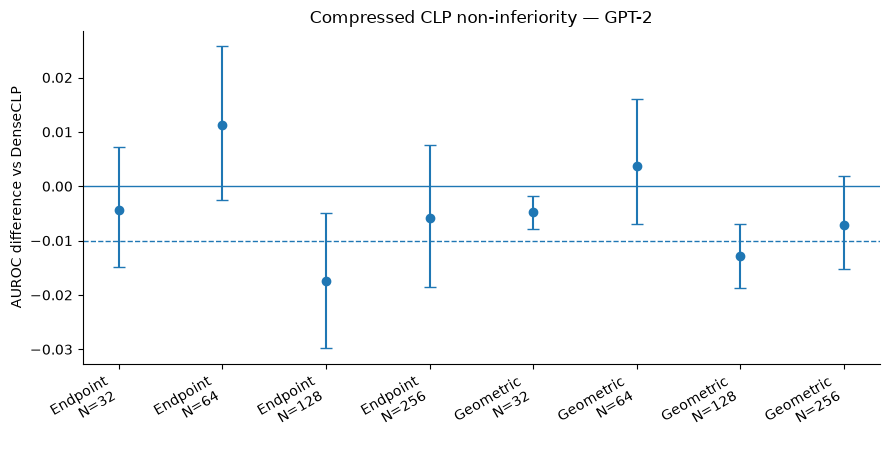

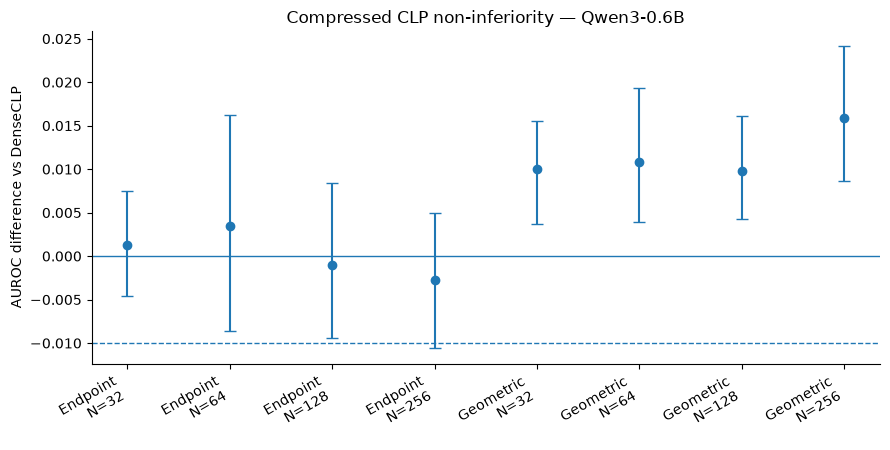

In [7]:
for scorer in primary["scorer"].unique():
    sub = primary[primary["scorer"] == scorer].copy()

    labels, means, lows, highs = [], [], [], []

    for method in ["Endpoint","Geometric"]:
        for N in sorted(sub["N"].unique()):
            r = sub[(sub["method"] == method) & (sub["N"] == N)].iloc[0]
            labels.append(f"{method}\nN={N}")
            means.append(r["mean_delta_vs_dense"])
            lows.append(r["mean_delta_vs_dense"] - r["ci95_lo"])
            highs.append(r["ci95_hi"] - r["mean_delta_vs_dense"])

    x = np.arange(len(labels))

    fig, ax = plt.subplots(figsize=(9.0,4.6))
    ax.errorbar(
        x, means,
        yerr=np.vstack([lows, highs]),
        fmt="o", capsize=4,
    )

    ax.axhline(0, linewidth=1)
    ax.axhline(-0.01, linestyle="--", linewidth=1)

    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=30, ha="right")
    ax.set_ylabel("AUROC difference vs DenseCLP")
    ax.set_title(f"Compressed CLP non-inferiority — {scorer}")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    fig.tight_layout()

    slug = scorer.lower().replace(".","").replace("-","_")
    fig.savefig(FIGURES / f"clp_noninferiority_{slug}.pdf", bbox_inches="tight")
    fig.savefig(FIGURES / f"clp_noninferiority_{slug}.png", dpi=200, bbox_inches="tight")
    plt.show()


## Figure — compression factor versus AUROC loss


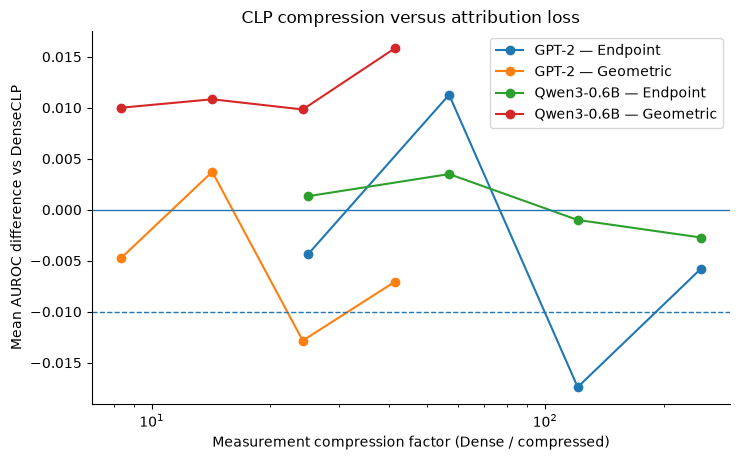

In [8]:
fig, ax = plt.subplots(figsize=(7.5,4.7))

for (scorer, method), sub in eff.groupby(["scorer","method"]):
    sub = sub.sort_values("compression_factor")
    ax.plot(
        sub["compression_factor"],
        sub["mean_delta_vs_dense"],
        marker="o",
        label=f"{scorer} — {method}",
    )

ax.axhline(0, linewidth=1)
ax.axhline(-0.01, linestyle="--", linewidth=1)

ax.set_xscale("log")
ax.set_xlabel("Measurement compression factor (Dense / compressed)")
ax.set_ylabel("Mean AUROC difference vs DenseCLP")
ax.set_title("CLP compression versus attribution loss")
ax.legend()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()
fig.savefig(FIGURES / "clp_noninferiority_efficiency.pdf", bbox_inches="tight")
fig.savefig(FIGURES / "clp_noninferiority_efficiency.png", dpi=200, bbox_inches="tight")
plt.show()


# Interpretation

Use the intersection of results across scorers.

A careful paper-level statement is:

> Under a predeclared 0.01-AUROC practical margin, compressed probing was non-inferior to dense probing in the split-level robustness analysis for [conditions that pass].

Avoid saying "statistically proven equivalent," because the repeated outer splits overlap.

If Endpoint passes broadly, that supports the practical \(O(1)\)-measurement claim.

If Geometric passes more broadly, that supports the \(O(\log N)\)-measurement claim.


In [9]:
print("=== PRIMARY NON-INFERIORITY RESULTS, delta=0.01 ===")
display(eff[
    [
        "scorer","N","method",
        "compressed_m","dense_m","compression_factor",
        "mean_delta_vs_dense","ci95_lo","ci95_hi",
        "bootstrap_prob_noninferior",
        "signflip_one_sided_p",
        "noninferior_ci_rule",
    ]
])

print("\n=== MARGIN SENSITIVITY ===")
display(sensitivity)


=== PRIMARY NON-INFERIORITY RESULTS, delta=0.01 ===


,scorer,N,method,compressed_m,dense_m,compression_factor,mean_delta_vs_dense,ci95_lo,ci95_hi,bootstrap_prob_noninferior,signflip_one_sided_p,noninferior_ci_rule
1,GPT-2,32,Endpoint,1,25,25.000000,-0.004333,-0.014946,0.007278,0.83880,0.181236,False
4,GPT-2,32,Geometric,3,25,8.333333,-0.004778,-0.007944,-0.001722,0.99935,0.003280,True
7,GPT-2,64,Endpoint,1,57,57.000000,0.011278,-0.002556,0.025722,0.99885,0.004400,True
10,GPT-2,64,Geometric,4,57,14.250000,0.003722,-0.006889,0.016112,0.99570,0.011300,True
13,GPT-2,128,Endpoint,1,121,121.000000,-0.017389,-0.029833,-0.005000,0.12400,0.865563,False
16,GPT-2,128,Geometric,5,121,24.200000,-0.012833,-0.018667,-0.006889,0.17855,0.814384,False
19,GPT-2,256,Endpoint,1,249,249.000000,-0.005778,-0.018611,0.007500,0.73195,0.274175,False
22,GPT-2,256,Geometric,6,249,41.500000,-0.007056,-0.015278,0.001944,0.74045,0.262815,False
25,Qwen3-0.6B,32,Endpoint,1,25,25.000000,0.001333,-0.004556,0.007500,0.99990,0.000960,True
28,Qwen3-0.6B,32,Geometric,3,25,8.333333,0.010000,0.003667,0.015556,1.00000,0.000040,True



=== MARGIN SENSITIVITY ===


margin                    0.005  0.010  0.020
scorer     N   method                        
GPT-2      32  Endpoint   False  False   True
               Geometric  False   True   True
           64  Endpoint    True   True   True
               Geometric  False   True   True
           128 Endpoint   False  False  False
               Geometric  False  False   True
           256 Endpoint   False  False   True
               Geometric  False  False   True
Qwen3-0.6B 32  Endpoint    True   True   True
               Geometric   True   True   True
           64  Endpoint   False   True   True
               Geometric   True   True   True
           128 Endpoint   False   True   True
               Geometric   True   True   True
           256 Endpoint   False  False   True
               Geometric   True   True   True